# Solving a simple durable–nondurable model (combined)

Step-by-step solution of the **nested** extension from `Text/DurableModelBasic.tex`,
Section *Extension: Search, Taste Shocks, and Stochastic Prices*:
- $LTV=0$, $\underline{a}=0$ (no borrowing)
- No maintenance / operation costs / permanent risk
- Single interest rate $\mathcal{R}=1+r$; adjustment cost $\tau$ retained
- **Three optional channels** (turn each off via parameters):
  1. **Taste shock** $\xi_t$: set `sigma_xi = 0` ($\xi\equiv 1$)
  2. **Directed search** $\varepsilon_t$: set `SearchCost = 0` (hard max)
  3. **Stochastic price** $p_t$: set `PriceShkStd = 0` ($p\equiv 1$)

Nested discrete problem:
$$v_t(m,n,p,\xi)=\max_{\varepsilon}\Big[(1-\varepsilon)\,v^{keep}+\varepsilon\,\xi\,v^{adj}(\ell,p)-\sigma(\varepsilon)\Big].$$

Adapts `DurableModel_Price_One_Period.ipynb`, `DurableModel_TasteShock_One_Period.ipynb`,
and `DurableModel_Search_One_Period.ipynb`.


In [79]:
# --- Imports and path setup ---
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as sp_optimize

ROOT = Path.cwd().resolve()
if ROOT.name == "Code":
    BG = ROOT.parent / "BackgroundInformation"
else:
    BG = ROOT / "BackgroundInformation"
sys.path.insert(0, str(BG))

from HARK.econforgeinterp import LinearFast
from HARK.interpolation import ValueFuncCRRA, LowerEnvelope2D, MargValueFuncCRRA
from HARK.ConsumptionSaving.ConsIndShockModel import utility, utility_inv, utilityP_inv
from HARK.dcegm import calc_nondecreasing_segments, upper_envelope
from HARK.distribution import expected, MeanOneLogNormal
from HARK.utilities import make_grid_exp_mult

from FUES import FUES_allPol
from utilities_Durable import (
    construct_grid,
    CRRAutilityP_inv_njit,
    CRRAutility_njit,
    MargValueFuncCRRA_dur,
    inv_MargValueFuncCRRA_dur,
    find_roots_in_interval,
    durable_solution_function_FUES_fast_search_noSS,
    HANKIncShkDstn_Truncated,
    vp_next_vPDFunc,
    vFunc_next,
    update_prob_grid_list_with_trunc,
    compute_cost_matrix,
    directed_search_function_scaled_matrix,
)

np.set_printoptions(precision=4, suppress=True)
print("Imports OK")


Imports OK


## Parameters

**Channel shutoffs** (set any to zero to turn that friction off):
- `sigma_xi = 0` → no taste shock ($\xi\equiv 1$)
- `SearchCost = 0` → no search frictions (hard max keep vs $\xi\,v^{adj}$)
- `PriceShkStd = 0` → no price risk ($p\equiv 1$)


In [80]:
# --- Preferences ---
CRRA = 2.0
DiscFac = 0.96
LivPrb = 1.0
alpha = 0.9
d_ubar = 1e-4

# --- Durables / frictions ---
dDepr = 0.15
adjC = 0.15
tau = adjC
MaintCost = 0.0
OpCost = 0.0

# --- Returns / borrowing ---
Rfree = 1.04
RSpread = 0.0
PermGroFac = 1.0
LTV = 0.0
BoroCnstArt = 0.0

# --- Channel 1: taste shock (sigma_xi=0 => OFF) ---
sigma_xi = 0.10
TasteShkCount = 11

# --- Channel 2: directed search (SearchCost=0 => OFF / hard max) ---
SearchCost = 0.1
ScaleBool = False
e_grid_count = 101

# --- Channel 3: stochastic prices (PriceShkStd=0 => OFF) ---
PriceShkCount = 5
PriceShkStd = 0.1

# --- Income shocks ---
PermShkStd = 0.0
PermShkCount = 1
TranShkStd = 0.1
TranShkCount = 7
UnempPrb = 0.0
IncUnemp = 0.0
truncation = 2
taxrate = 0.0
labor = 1.0
wage = 1.0

def TranShkMean_Func(taxrate, labor, wage):
    return (1.0 - taxrate) * labor * wage

use_expected = False
use_TransitionMatrix = True
assert use_expected ^ use_TransitionMatrix

nNrmMax, nNrmCount = 5.0, 40
mNrmMax, mNrmCount = 8.0, 50
xNrmMax, xNrmCount = 12.0, 80
aNrmMax, aNrmCount = 8.0, 50
aXtraMax = aNrmMax
NestFac = 2
grid_type = "exp_mult"
tol_combine = 1e-4
TranMatrix_mCount = 1010
TranMatrix_bCount = 1000

def CRRAutility(C, D):
    u_inner = (C ** alpha) * ((D + d_ubar) ** (1.0 - alpha))
    return utility(u_inner, CRRA)

def CRRAutility_inv(C, D):
    return utility_inv(CRRAutility(C, D), CRRA)

def CRRAutilityP(C, D):
    return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)
            * (D + d_ubar) ** ((1.0 - alpha) * (1.0 - CRRA)))

def CRRAutilityPD(C, D):
    return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))
            * (D + d_ubar) ** ((1.0 - alpha) * (1.0 - CRRA) - 1.0))

def CRRAutilityP_inv(Cmarg, D):
    power = 1.0 / (alpha * (1.0 - CRRA) - 1.0)
    return (Cmarg / (alpha * (D + d_ubar) ** ((1.0 - alpha) * (1.0 - CRRA)))) ** power

def tau_func(x):
    return np.ones_like(np.asarray(x, dtype=float)) * tau

print("Parameters set.")
print("EoP method:", "expected" if use_expected else "TransitionMatrix")
print(
    f"Channels — taste: {'ON' if sigma_xi > 0 else 'OFF'} (sigma_xi={sigma_xi}), "
    f"search: {'ON' if SearchCost > 0 else 'OFF'} (S={SearchCost}), "
    f"price: {'ON' if PriceShkStd > 0 else 'OFF'} (sigma_p={PriceShkStd})"
)


Parameters set.
EoP method: TransitionMatrix
Channels — taste: ON (sigma_xi=0.1), search: ON (S=0.1), price: ON (sigma_p=0.1)


## Shock discretization (taste + price) and search cost

Discretize mean-one log-normals for $\xi_t$ and $p_t$. When `sigma_xi=0` or `PriceShkStd=0`,
that channel collapses to a single atom at 1. Search uses
$\sigma(\varepsilon)=S[\varepsilon+(1-\varepsilon)\log(1-\varepsilon)]$; `SearchCost=0` recovers a hard max.


In [81]:
# --- Price-shock discretization ---
PriceShkDstn = MeanOneLogNormal(sigma=PriceShkStd).discretize(PriceShkCount) if PriceShkStd > 0.0 else None
if PriceShkDstn is not None:
    PriceShkVals = PriceShkDstn.atoms[0]
    PriceShkWeights = PriceShkDstn.pmv
else:
    PriceShkVals = np.array([1.0])
    PriceShkWeights = np.array([1.0])
nPrice = len(PriceShkVals)
print(f"Price-shock nodes: {nPrice}, E[p]={np.dot(PriceShkWeights, PriceShkVals):.6f}")

# --- Taste-shock discretization ---
tasteShkDstn = MeanOneLogNormal(sigma=sigma_xi).discretize(TasteShkCount) if sigma_xi > 0.0 else None
if tasteShkDstn is not None:
    tasteShkVals = tasteShkDstn.atoms[0]
    tasteShkWeights = tasteShkDstn.pmv
else:
    tasteShkVals = np.array([1.0])
    tasteShkWeights = np.array([1.0])
nTaste = len(tasteShkVals)
print(f"Taste-shock nodes: {nTaste}, E[xi]={np.dot(tasteShkWeights, tasteShkVals):.6f}")


Price-shock nodes: 5, E[p]=1.000000
Taste-shock nodes: 11, E[xi]=1.000000


## Grids

In [82]:
# nNrmGrid
nNrmGrid = construct_grid(0.001, nNrmMax, nNrmCount - 1, grid_type, NestFac)
nNrmGrid = np.unique(np.append(0.0, nNrmGrid))

# mNrmGrid
mNrmGrid = construct_grid(0.001, mNrmMax, mNrmCount - 1, grid_type, NestFac)
mNrmGrid = np.unique(np.append(0.0, mNrmGrid))

# xNrmGrid (liquidity = m + (1-tau)n)
xNrmGrid = construct_grid(0.001, xNrmMax, xNrmCount - 1, grid_type, NestFac)
xNrmGrid = np.unique(np.append(0.0, xNrmGrid))

# aNrmGrid (a >= 0)
aNrmGrid = construct_grid(0.001, aNrmMax, aNrmCount - 1, grid_type, NestFac)
aNrmGrid = np.unique(np.append(0.0, aNrmGrid))

# End-of-period durable grid (same span as n)
dNrmGrid = nNrmGrid.copy()

print(f"n: {len(nNrmGrid)}, m: {len(mNrmGrid)}, x: {len(xNrmGrid)}, a: {len(aNrmGrid)}")


n: 40, m: 50, x: 80, a: 50


In [83]:
# --- Search cost function (ScaleBool=False) ---
e_grid = np.linspace(0.0, 1.0, e_grid_count)
if ScaleBool:
    raise NotImplementedError("Constant-cost branch only.")
SearchCost_func = LinearFast(np.ones_like(xNrmGrid) * SearchCost, [xNrmGrid])
print(f"SearchCost={SearchCost}, e_grid points={len(e_grid)}")


SearchCost=0.1, e_grid points=101


In [84]:
# --- Plotting helper used after each solution step ---
def plot_keeper_adjuster_combined(
    n_vals,
    m_grid,
    c_keep, d_keep,
    c_adj, d_adj,
    c_comb, d_comb,
    adjusting=None,
    title="",
):
    """Plot c and d vs m for a few n, for keeper / adjuster / combined."""
    n_plot = np.atleast_1d(n_vals)
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
    titles = ["Keeper", "Adjuster", "Combined"]
    c_funcs = [c_keep, c_adj, c_comb]
    d_funcs = [d_keep, d_adj, d_comb]

    for col, (ttl, cf, df) in enumerate(zip(titles, c_funcs, d_funcs)):
        for n0 in n_plot:
            n_vec = np.full_like(m_grid, n0, dtype=float)
            axes[0, col].plot(m_grid, cf(n_vec, m_grid), label=fr"$n={n0:.2f}$")
            axes[1, col].plot(m_grid, df(n_vec, m_grid), label=fr"$n={n0:.2f}$")
        axes[0, col].set_title(ttl)
        axes[0, col].set_ylabel(r"$c(n,m)$")
        axes[1, col].set_ylabel(r"$d(n,m)$")
        axes[1, col].set_xlabel(r"$m$")
        axes[0, col].legend(fontsize=8)
        axes[1, col].legend(fontsize=8)

    if adjusting is not None:
        ax = axes[0, 2].twinx()
        n0 = n_plot[len(n_plot) // 2]
        n_vec = np.full_like(m_grid, n0, dtype=float)
        ax.plot(m_grid, adjusting(n_vec, m_grid), "k--", alpha=0.4, label="adjusting")
        ax.set_ylabel("adjusting")
        ax.set_ylim(-0.05, 1.05)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [85]:
def plot_adjusting_heatmap(nGrid, mGrid, array, title, cbar_label="adjusting"):
    """
    2-D heatmap of the (discrete or soft) adjusting indicator over the (n,m) grid:
    m on the x-axis, n on the y-axis, color scale fixed to [0,1].
    """
    fig, ax = plt.subplots(figsize=(7, 5))
    pcm = ax.pcolormesh(mGrid, nGrid, array, cmap="viridis", shading="auto", vmin=0.0, vmax=1.0)
    fig.colorbar(pcm, ax=ax, label=cbar_label)
    ax.set_xlabel(r"$m$")
    ax.set_ylabel(r"$n$")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


## Terminal period

- **Keeper:** $d=n$, $c=m$
- **Adjuster:** $c=\alpha\ell$, $d=(1-\alpha)\ell/p$ (price-contingent; $\xi$ does not enter)
- **Combined:** nested search + taste + price integration


In [86]:
# ===== Terminal: Keeper =====
# From solve_terminal_solution (LTV=0 branch): c=m, d=n, a=0
mNrmGrid_T = np.append(mNrmGrid, mNrmGrid[-1] + 1.0)
nNrmGrid_T = nNrmGrid.copy()

keep_shape = (len(nNrmGrid_T), len(mNrmGrid_T))
cFuncKeep_T_arr = np.zeros(keep_shape)
dFuncKeep_T_arr = np.zeros(keep_shape)
aFuncKeep_T_arr = np.zeros(keep_shape)
inv_vFuncKeep_T_arr = np.zeros(keep_shape)

for i_n, n0 in enumerate(nNrmGrid_T):
    dFuncKeep_T_arr[i_n, :] = n0
    cFuncKeep_T_arr[i_n, :] = mNrmGrid_T
    aFuncKeep_T_arr[i_n, :] = mNrmGrid_T - cFuncKeep_T_arr[i_n, :]  # = 0
    inv_vFuncKeep_T_arr[i_n, :] = CRRAutility_inv(cFuncKeep_T_arr[i_n, :], dFuncKeep_T_arr[i_n, :])

vPFuncKeep_T_arr = CRRAutilityP(cFuncKeep_T_arr, dFuncKeep_T_arr)
vPDFuncKeep_T_arr = CRRAutilityPD(cFuncKeep_T_arr, dFuncKeep_T_arr)

cFuncKeep_T = LinearFast(cFuncKeep_T_arr, [nNrmGrid_T, mNrmGrid_T])
dFuncKeep_T = LinearFast(dFuncKeep_T_arr, [nNrmGrid_T, mNrmGrid_T])
inv_vFuncKeep_T = LinearFast(inv_vFuncKeep_T_arr, [nNrmGrid_T, mNrmGrid_T])
vFuncKeep_T = ValueFuncCRRA(inv_vFuncKeep_T, CRRA)
vPFuncKeep_T = MargValueFuncCRRA_dur(cFuncKeep_T, dFuncKeep_T, alpha, d_ubar, CRRA)

print("Terminal keeper done.")


Terminal keeper done.


C:\Users\adria\AppData\Local\Temp\ipykernel_11500\2401902331.py:73: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)
C:\Users\adria\AppData\Local\Temp\ipykernel_11500\2401902331.py:77: RuntimeWarning: divide by zero encountered in power
  return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))


In [87]:
# ===== Terminal: Adjuster (analytical; LTV=0 => c=alpha*ell, d=(1-alpha)*ell/p) =====
# See equation (price_terminal): c does NOT depend on price; d is divided by p_k.
# Taste shock does not enter the inner maximization.
# NOTE: LinearFast requires >=2 nodes along each grid axis, so when PriceShkStd=0
# (single price atom) we build 1-D / 2-D interpolants without the price axis.

nPrice = len(PriceShkVals)

### Adjuster in 2D (prices and liquidity)
adjuster_price_shape = (nPrice, len(xNrmGrid))
dFuncAdj_T_2d = np.zeros(adjuster_price_shape)
cFuncAdj_T_2d = np.zeros(adjuster_price_shape)
inv_vFuncAdj_T_2d = np.zeros(adjuster_price_shape)

for i_p, p0 in enumerate(PriceShkVals):
    dFuncAdj_T_2d[i_p] = (1.0 - alpha) * xNrmGrid / p0
    cFuncAdj_T_2d[i_p] = alpha * xNrmGrid
    inv_vFuncAdj_T_2d[i_p] = CRRAutility_inv(cFuncAdj_T_2d[i_p], dFuncAdj_T_2d[i_p])

if nPrice >= 2:
    cFuncAdj_T = LinearFast(cFuncAdj_T_2d, [PriceShkVals, xNrmGrid])
    dFuncAdj_T = LinearFast(dFuncAdj_T_2d, [PriceShkVals, xNrmGrid])
    inv_vFuncAdj_T = LinearFast(inv_vFuncAdj_T_2d, [PriceShkVals, xNrmGrid])
else:
    cFuncAdj_T = LinearFast(cFuncAdj_T_2d[0], [xNrmGrid])
    dFuncAdj_T = LinearFast(dFuncAdj_T_2d[0], [xNrmGrid])
    inv_vFuncAdj_T = LinearFast(inv_vFuncAdj_T_2d[0], [xNrmGrid])
vPFuncAdj_T = MargValueFuncCRRA_dur(cFuncAdj_T, dFuncAdj_T, alpha, d_ubar, CRRA)

# Map adjuster onto (p, n, m)
shape_T = (nPrice, len(nNrmGrid_T), len(mNrmGrid_T))
cFuncAdj_SOL_T = np.zeros(shape_T)
dFuncAdj_SOL_T = np.zeros(shape_T)
aFuncAdj_SOL_T = np.zeros(shape_T)
inv_vFuncAdj_SOL_T = np.zeros(shape_T)
vPDFuncAdj_SOL_T = np.zeros(shape_T)

for i_p, p0 in enumerate(PriceShkVals):
    for i_n, n0 in enumerate(nNrmGrid_T):
        n_aux = np.full(len(mNrmGrid_T), n0)
        tau_nm = tau_func(n_aux + mNrmGrid_T)
        x_aux = np.clip(mNrmGrid_T + (1.0 - tau_nm) * n_aux, 0.0, None)
        dFuncAdj_SOL_T[i_p, i_n, :] = (1.0 - alpha) * x_aux / p0
        cFuncAdj_SOL_T[i_p, i_n, :] = alpha * x_aux
        aFuncAdj_SOL_T[i_p, i_n, :] = (
            x_aux - cFuncAdj_SOL_T[i_p, i_n, :] - p0 * dFuncAdj_SOL_T[i_p, i_n, :]
        )
        inv_vFuncAdj_SOL_T[i_p, i_n, :] = CRRAutility_inv(
            cFuncAdj_SOL_T[i_p, i_n, :], dFuncAdj_SOL_T[i_p, i_n, :]
        )
        vPDFuncAdj_SOL_T[i_p, i_n, :] = (1.0 - tau_nm) * CRRAutilityP(
            cFuncAdj_SOL_T[i_p, i_n, :], dFuncAdj_SOL_T[i_p, i_n, :]
        )

vPFuncAdj_SOL_T = CRRAutilityP(cFuncAdj_SOL_T, dFuncAdj_SOL_T)

if nPrice >= 2:
    cFuncAdj_NM_T = LinearFast(cFuncAdj_SOL_T, [PriceShkVals, nNrmGrid_T, mNrmGrid_T])
    dFuncAdj_NM_T = LinearFast(dFuncAdj_SOL_T, [PriceShkVals, nNrmGrid_T, mNrmGrid_T])
else:
    cFuncAdj_NM_T = LinearFast(cFuncAdj_SOL_T[0], [nNrmGrid_T, mNrmGrid_T])
    dFuncAdj_NM_T = LinearFast(dFuncAdj_SOL_T[0], [nNrmGrid_T, mNrmGrid_T])

print(f"Max |budget resid| = {np.max(np.abs(aFuncAdj_SOL_T)):.2e}")
print(f"Terminal adjuster done (nPrice={nPrice}).")


Max |budget resid| = 9.99e-16
Terminal adjuster done (nPrice=5).


C:\Users\adria\AppData\Local\Temp\ipykernel_11500\2401902331.py:73: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)


In [88]:
def combine_search_taste_price(
    price_vals, price_weights,
    taste_vals, taste_weights,
    cAdj, dAdj, aAdj, inv_vAdj, vPAdj, vPDAdj,
    cKeep, dKeep, aKeep, inv_vKeep, vPKeep, vPDKeep,
    nGrid, mGrid, SearchCost_func_, e_grid_, CRRA_,
):
    """
    Nested combine over (p_k, xi_j):
      v = max_eps[(1-eps) vKeep + eps * xi * vAdj(p) - sigma(eps)],
    then integrate with mu_p * mu_xi.

    Shutoffs: PriceShkStd=0, sigma_xi=0, SearchCost=0 (hard max via zero costs).
    Adjuster arrays: (n_price, n_n, n_m). Keeper: (n_n, n_m).
    """
    n_price = cAdj.shape[0]
    keep_shape = cKeep.shape

    vKeep_level = utility(inv_vKeep, CRRA_)
    vAdj_level = utility(inv_vAdj, CRRA_)

    search_cost_matrix = np.zeros(keep_shape)
    for i_n, n0 in enumerate(nGrid):
        n_aux = np.full(len(mGrid), n0)
        search_cost_matrix[i_n, :] = SearchCost_func_(n_aux + mGrid)
    Costs_matrix = compute_cost_matrix(search_cost_matrix, e_grid_)
    mNrmGridMin = np.zeros(1)

    barC = np.zeros(keep_shape)
    barD = np.zeros(keep_shape)
    barA = np.zeros(keep_shape)
    barV = np.zeros(keep_shape)
    barVP = np.zeros(keep_shape)
    barVPD = np.zeros(keep_shape)
    barEps = np.zeros(keep_shape)

    for i_p in range(n_price):
        w_p = price_weights[i_p]
        for xi_j, w_xi in zip(taste_vals, taste_weights):
            w = w_p * w_xi
            vAdj_scaled = xi_j * vAdj_level[i_p]
            vPAdj_scaled = xi_j * vPAdj[i_p]
            vPDAdj_scaled = xi_j * vPDAdj[i_p]

            vAdj_aux = np.where(vAdj_scaled == -np.inf, -1e12, vAdj_scaled)
            vKeep_aux = np.where(vKeep_level == -np.inf, -1e12, vKeep_level)
            vPAdj_aux = np.where(vPAdj_scaled == np.inf, 1e12, vPAdj_scaled)
            vPDAdj_aux = np.where(vPDAdj_scaled == np.inf, 1e12, vPDAdj_scaled)
            vPKeep_aux = np.where(vPKeep == np.inf, 1e12, vPKeep)
            vPDKeep_aux = np.where(vPDKeep == np.inf, 1e12, vPDKeep)

            (
                eps_ij, _cost_ij, v_ij,
                c_ij, d_ij, a_ij, vP_ij, vPD_ij,
            ) = directed_search_function_scaled_matrix(
                nGrid, mGrid, mNrmGridMin, e_grid_, Costs_matrix,
                vAdj_aux, vKeep_aux,
                cAdj[i_p], cKeep,
                dAdj[i_p], dKeep,
                aAdj[i_p], aKeep,
                vPAdj_aux, vPKeep_aux,
                vPDAdj_aux, vPDKeep_aux,
            )

            v_ij = np.array(v_ij, copy=True)
            vP_ij = np.array(vP_ij, copy=True)
            vPD_ij = np.array(vPD_ij, copy=True)

            cond_inf_v = (
                ((eps_ij == 1.0) & (vAdj_scaled == -np.inf))
                | ((eps_ij == 0.0) & (vKeep_level == -np.inf))
                | (((eps_ij > 0.0) & (eps_ij < 1.0))
                   & ((vAdj_scaled == -np.inf) | (vKeep_level == -np.inf)))
            )
            v_ij[cond_inf_v] = -np.inf

            cond_inf_vP = (
                ((eps_ij == 1.0) & (vPAdj_scaled == np.inf))
                | ((eps_ij == 0.0) & (vPKeep == np.inf))
                | (((eps_ij > 0.0) & (eps_ij < 1.0))
                   & ((vPAdj_scaled == np.inf) | (vPKeep == np.inf)))
            )
            vP_ij[cond_inf_vP] = np.inf

            cond_inf_vPD = (
                ((eps_ij == 1.0) & (vPDAdj_scaled == np.inf))
                | ((eps_ij == 0.0) & (vPDKeep == np.inf))
                | (((eps_ij > 0.0) & (eps_ij < 1.0))
                   & ((vPDAdj_scaled == np.inf) | (vPDKeep == np.inf)))
            )
            vPD_ij[cond_inf_vPD] = np.inf

            barC += w * c_ij
            barD += w * d_ij
            barA += w * a_ij
            barV += w * v_ij
            barVP += w * vP_ij
            barVPD += w * vPD_ij
            barEps += w * eps_ij

    return barC, barD, barA, barV, barVP, barVPD, barEps


In [89]:
# ===== Terminal: nested search + taste + price combine =====
(
    cFunc_T_arr, dFunc_T_arr, aFunc_T_arr,
    barV_T_arr, vPFunc_T_arr, vPDFunc_T_arr, adjusting_T_arr,
) = combine_search_taste_price(
    PriceShkVals, PriceShkWeights,
    tasteShkVals, tasteShkWeights,
    cFuncAdj_SOL_T, dFuncAdj_SOL_T, aFuncAdj_SOL_T,
    inv_vFuncAdj_SOL_T, vPFuncAdj_SOL_T, vPDFuncAdj_SOL_T,
    cFuncKeep_T_arr, dFuncKeep_T_arr, aFuncKeep_T_arr,
    inv_vFuncKeep_T_arr, vPFuncKeep_T_arr, vPDFuncKeep_T_arr,
    nNrmGrid_T, mNrmGrid_T, SearchCost_func, e_grid, CRRA,
)

inv_vFunc_T_arr = utility_inv(barV_T_arr, CRRA)
cFunc_T = LinearFast(cFunc_T_arr, [nNrmGrid_T, mNrmGrid_T])
dFunc_T = LinearFast(dFunc_T_arr, [nNrmGrid_T, mNrmGrid_T])
inv_vFunc_T = LinearFast(inv_vFunc_T_arr, [nNrmGrid_T, mNrmGrid_T])
vFunc_T = ValueFuncCRRA(inv_vFunc_T, CRRA)
vPFunc_T = LinearFast(vPFunc_T_arr, [nNrmGrid_T, mNrmGrid_T])
vPDFunc_T = LinearFast(vPDFunc_T_arr, [nNrmGrid_T, mNrmGrid_T])
inv_vPFunc_T = LinearFast(utilityP_inv(vPFunc_T_arr, CRRA), [nNrmGrid_T, mNrmGrid_T])
inv_vPDFunc_T = LinearFast(utilityP_inv(vPDFunc_T_arr, CRRA), [nNrmGrid_T, mNrmGrid_T])
adjusting_T = LinearFast(adjusting_T_arr, [nNrmGrid_T, mNrmGrid_T])

print("Terminal combined done. Mean E[eps*]:", adjusting_T_arr.mean())
print("adjusting range:", adjusting_T_arr.min(), "->", adjusting_T_arr.max())


Terminal combined done. Mean E[eps*]: 0.623394741532977
adjusting range: 0.041090909090909095 -> 1.0000000000000002


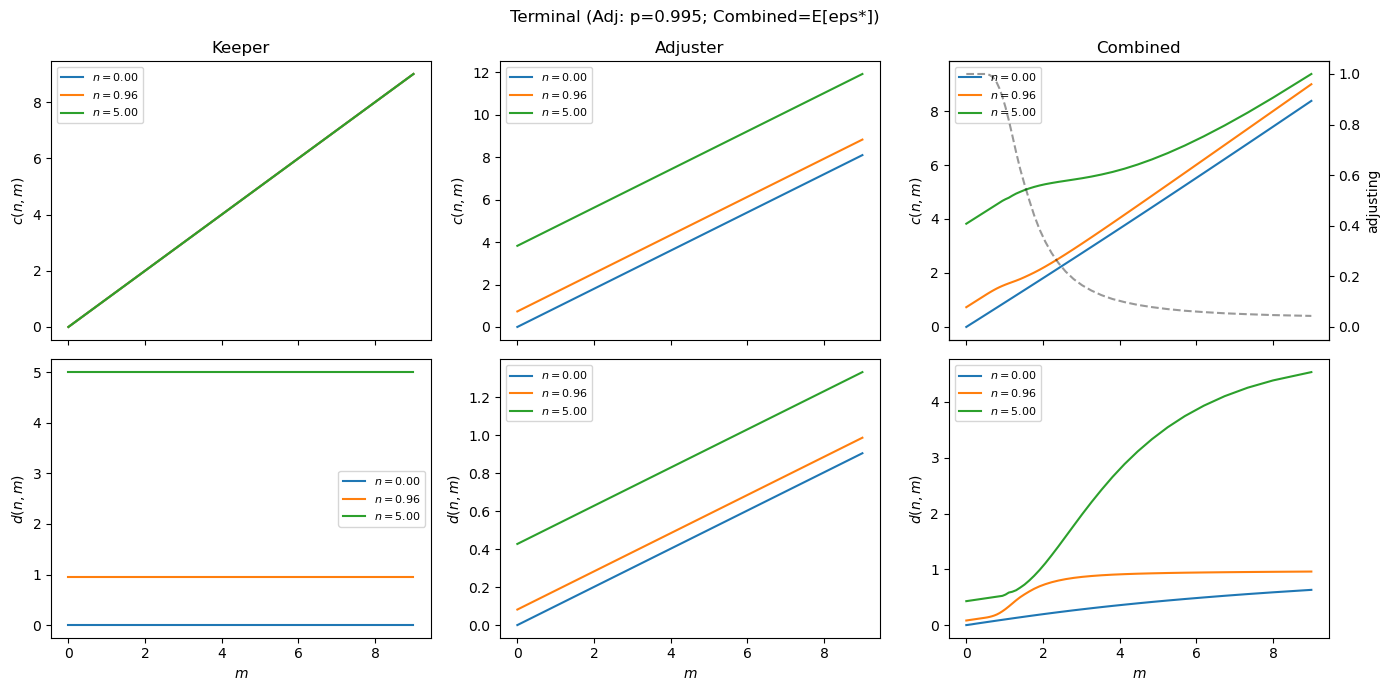

In [90]:
# --- Plot terminal policies ---
n_show = nNrmGrid_T[np.linspace(1, len(nNrmGrid_T) - 1, 3, dtype=int)]
i_p0 = int(np.argmin(np.abs(PriceShkVals - 1.0)))
cFuncAdj_NM_T_p0 = LinearFast(cFuncAdj_SOL_T[i_p0], [nNrmGrid_T, mNrmGrid_T])
dFuncAdj_NM_T_p0 = LinearFast(dFuncAdj_SOL_T[i_p0], [nNrmGrid_T, mNrmGrid_T])
plot_keeper_adjuster_combined(
    n_show, mNrmGrid_T,
    cFuncKeep_T, dFuncKeep_T,
    cFuncAdj_NM_T_p0, dFuncAdj_NM_T_p0,
    cFunc_T, dFunc_T,
    adjusting=adjusting_T,
    title=f"Terminal (Adj: p={PriceShkVals[i_p0]:.3f}; Combined=E[eps*])",
)


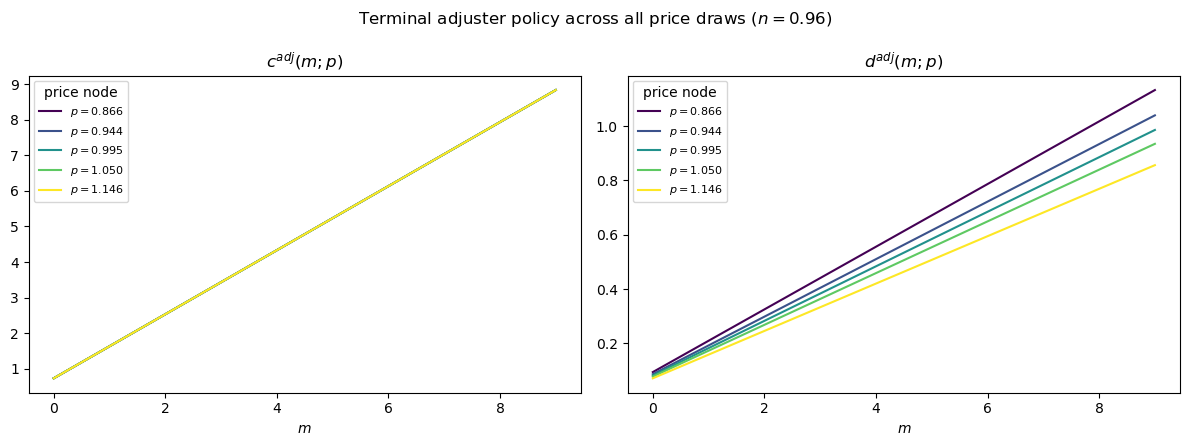

Max spread in c^adj across price nodes (should be ~0): 0.00e+00


In [91]:
# --- Adjuster policy for ALL price draws, overlaid in the same graph ---
# c^adj(.;p_k), d^adj(.;p_k) at a representative n, for every price node p_k.
i_n0 = len(n_show) // 2
n0_overlay = n_show[i_n0]
i_n0_full = int(np.argmin(np.abs(nNrmGrid_T - n0_overlay)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
cmap = plt.get_cmap("viridis")
for i_p, p0 in enumerate(PriceShkVals):
    color = cmap(i_p / max(nPrice - 1, 1))
    axes[0].plot(mNrmGrid_T, cFuncAdj_SOL_T[i_p, i_n0_full, :], color=color, label=fr"$p={p0:.3f}$")
    axes[1].plot(mNrmGrid_T, dFuncAdj_SOL_T[i_p, i_n0_full, :], color=color, label=fr"$p={p0:.3f}$")

axes[0].set_title(r"$c^{adj}(m; p)$")
axes[1].set_title(r"$d^{adj}(m; p)$")
for ax in axes:
    ax.set_xlabel(r"$m$")
    ax.legend(fontsize=8, title="price node")
fig.suptitle(fr"Terminal adjuster policy across all price draws ($n={nNrmGrid_T[i_n0_full]:.2f}$)")
fig.tight_layout()
plt.show()

# Sanity check: since c*=alpha*ell is price-independent, all c^adj curves above should
# coincide; d^adj should scale as 1/p across price nodes.
c_spread = np.ptp(cFuncAdj_SOL_T[:, i_n0_full, :], axis=0).max()
print(f"Max spread in c^adj across price nodes (should be ~0): {c_spread:.2e}")


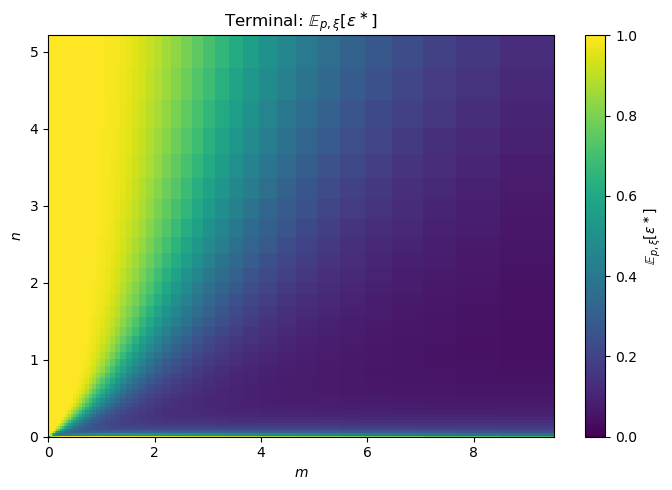

In [92]:
# --- Heatmap: E[eps*] over (n,m), terminal ---
plot_adjusting_heatmap(
    nNrmGrid_T, mNrmGrid_T, adjusting_T_arr,
    title=r"Terminal: $\mathbb{E}_{p,\xi}[\varepsilon^\ast]$",
    cbar_label=r"$\mathbb{E}_{p,\xi}[\varepsilon^\ast]$",
)


## Period $T-1$

1. End-of-period values from integrated $\bar v_T$
2. Keeper via EGM + DCEGM (unchanged by $p,\xi$)
3. Adjuster via FOC + FUES **once per price node**
4. Nested combine over $(p_k,\xi_j)$ with directed search


### Income process

Built with the same truncated HANK engines as
`DurableModel_Fast_Latest.construct_lognormal_income_process_unemployment_truncated`
(`HANKIncShkDstn_Truncated`). For the basic model: permanent-shock std = 0 and
unemployment probability = 0, with truncation and `TranShkMean_Func` retained.

If `use_TransitionMatrix`, also build dense $m$/$b$ grids and `probGrid_income`
as in `updatemNrmGrid_income` / `updatebNrmGrid_income` / `updateBM_TranMatrix_numba`.


In [93]:
# ===== Exact income process (DurableModel_Fast_Latest) =====
IncShkDstn = HANKIncShkDstn_Truncated(
    sigma_Perm=PermShkStd,
    sigma_Tran=TranShkStd,
    n_approx_Perm=PermShkCount if PermShkStd > 0.0 else 1,
    n_approx_Tran=TranShkCount if TranShkStd > 0.0 else 1,
    UnempPrb=UnempPrb,
    IncUnemp=IncUnemp,
    taxrate=taxrate,
    TranShkMean_Func=TranShkMean_Func,
    labor=labor,
    wage=wage,
    truncation=truncation,
    neutral_measure=False,
)

ShkPrbsNext = IncShkDstn.pmv
PermShkValsNext = IncShkDstn.atoms[0]
TranShkValsNext = IncShkDstn.atoms[1]

# Permanent-only nodes (TransitionMatrix step 5 in the full solver)
PermShkValsNext_only = np.unique(PermShkValsNext)
ShkPrbsNext_PermShk = np.ones_like(PermShkValsNext_only) / len(PermShkValsNext_only)

TranShkMinNext = float(np.min(TranShkValsNext))
PermShkMinNext = float(np.min(PermShkValsNext))

print("Perm atoms:", np.unique(PermShkValsNext))
print("Tran atoms:", np.unique(np.round(TranShkValsNext, 6)))
print("E[psi] =", np.dot(ShkPrbsNext, PermShkValsNext))
print("E[theta] =", np.dot(ShkPrbsNext, TranShkValsNext))
print("n shocks =", len(ShkPrbsNext))

# --- TransitionMatrix grids / lottery (only built if selected) ---
if use_TransitionMatrix:
    # Same formulas as updatemNrmGrid_income / updatebNrmGrid_income with LTV=0
    mNrmMax_income = (
        Rfree / (PermGroFac * PermShkMinNext) * aXtraMax + float(np.max(TranShkValsNext))
    )
    mNrmGrid_income = make_grid_exp_mult(0.0001, mNrmMax_income, TranMatrix_mCount, timestonest=1)
    mNrmGrid_income = np.asarray(mNrmGrid_income).flatten()

    bNrmGrid_income = make_grid_exp_mult(0.0, mNrmMax_income - 1.0, TranMatrix_bCount, timestonest=1)
    bNrmGrid_income = np.asarray(bNrmGrid_income).flatten()

    # updateBM_TranMatrix_numba (UnempPrb=0 branch)
    IncUnemp_Std = 0.1
    mu_transformed = (1.0 - UnempPrb * IncUnemp) / (1.0 - UnempPrb) if UnempPrb < 1.0 else 1.0
    b_mesh, m_mesh = np.meshgrid(bNrmGrid_income, mNrmGrid_income, indexing="ij")
    diff_grid = m_mesh - b_mesh
    z = TranShkMean_Func(taxrate, labor, wage)
    probGrid_income = update_prob_grid_list_with_trunc(
        1,
        diff_grid,
        np.array([TranShkStd]),
        np.array([UnempPrb]),
        np.array([IncUnemp if UnempPrb > 0 else 1e-12]),
        np.array([mu_transformed]),
        np.array([TranShkMinNext]),
        np.array([z]),
        IncUnemp_Std,
    )[0]
    print("TransitionMatrix grids: m =", len(mNrmGrid_income), "b =", len(bNrmGrid_income))
    print("probGrid_income shape:", probGrid_income.shape)
else:
    mNrmGrid_income = None
    bNrmGrid_income = None
    probGrid_income = None
    print("TransitionMatrix grids not built (use_expected=True).")


Perm atoms: [1.]
Tran atoms: [0.8    0.8504 0.9186 0.9591 0.9951 1.0324 1.078  1.1664]
E[psi] = 1.0
E[theta] = 1.0
n shocks = 8
TransitionMatrix grids: m = 1010 b = 1000
probGrid_income shape: (1000, 1010)


### End-of-period functions

Laws of motion (basic model): $m'=\mathcal{R}a+\theta$, $n'=(1-\delta)d$
(with $\psi=G=1$, MaintCost=OpCost=0).

Integration method selected by the Booleans above:
- **`use_expected`**: `HARK.distribution.expected` with `vp_next_vPDFunc` / `vFunc_next`
  (same as `expected_method == "expected"` in `solve_DurableConsumer`)
- **`use_TransitionMatrix`**: $b\to m$ lottery (`probGrid_income`) then permanent-shock nodes
  (same as `expected_method == "TransitionMatrix"`, CPU path)


In [94]:
# ===== End-of-period values (exact branches from solve_DurableConsumer) =====
inv_vPFuncNext = inv_vPFunc_T
inv_vPDFuncNext = inv_vPDFunc_T
inv_vFunc_next = inv_vFunc_T

# a >= 0 => single interest factor (RSpread unused)
R_vec = np.full(len(aNrmGrid), Rfree)

post_shape = (len(dNrmGrid), len(aNrmGrid))
EndOfPrdvPOne = np.zeros(post_shape)
EndOfPrdvPTwo = np.zeros(post_shape)
EndOfPrdvPD = np.zeros(post_shape)
EndOfPrdv = np.zeros(post_shape)
inv_EndOfPrdv = np.zeros(post_shape)

if use_expected:
    # --- expected_method == "expected" ---
    for i_d in range(len(dNrmGrid)):
        EndOfPrdvPOne[i_d] = (
            DiscFac * LivPrb * PermGroFac ** (-CRRA) * R_vec
            * expected(
                vp_next_vPDFunc,
                IncShkDstn,
                args=(inv_vPFuncNext, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        EndOfPrdvPTwo[i_d] = (
            DiscFac * LivPrb * PermGroFac ** (-CRRA) * (R_vec + OpCost + MaintCost * dDepr)
            * expected(
                vp_next_vPDFunc,
                IncShkDstn,
                args=(inv_vPFuncNext, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        EndOfPrdvPD[i_d] = (
            DiscFac * LivPrb * PermGroFac ** (-CRRA) * (1.0 - dDepr * (1.0 - MaintCost))
            * expected(
                vp_next_vPDFunc,
                IncShkDstn,
                args=(inv_vPDFuncNext, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        EndOfPrdv[i_d] = (
            DiscFac * LivPrb
            * expected(
                vFunc_next,
                IncShkDstn,
                args=(utility_inv, inv_vFunc_next, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        inv_EndOfPrdv[i_d, 1:] = utility_inv(EndOfPrdv[i_d, 1:], CRRA)

elif use_TransitionMatrix:
    # --- expected_method == "TransitionMatrix" (CPU path) ---
    nNrmGridNow = dNrmGrid  # beginning-of-next-period n grid = end-of-period d grid
    _n2d = np.repeat(nNrmGridNow[:, np.newaxis], len(mNrmGrid_income), axis=1)
    _m2d = np.tile(mNrmGrid_income[np.newaxis, :], (len(nNrmGridNow), 1))

    inv_vPFuncNext_array = np.clip(inv_vPFuncNext(_n2d, _m2d), 0, None)
    inv_vPDFuncNext_array = np.clip(inv_vPDFuncNext(_n2d, _m2d), 0, None)
    inv_vFuncNext_array = np.clip(inv_vFunc_next(_n2d, _m2d), 0, None)

    vFuncNext_array = utility(inv_vFuncNext_array, CRRA)
    vPDFuncNext_array = inv_vPDFuncNext_array ** (-CRRA)
    vPFuncNext_array = inv_vPFuncNext_array ** (-CRRA)
    vPDFuncNext_array[np.isinf(vPDFuncNext_array)] = 1e16
    vPFuncNext_array[np.isinf(vPFuncNext_array)] = 1e16
    vFuncNext_array[np.isinf(vFuncNext_array)] = -1e16

    # Pre-multiply by lottery matrix: E[· | b, n]
    Interm_vP_array = np.dot(probGrid_income, vPFuncNext_array.T)    # (nB, nN)
    Interm_vPD_array = np.dot(probGrid_income, vPDFuncNext_array.T)
    Interm_v_array = np.dot(probGrid_income, vFuncNext_array.T)

    Interm_inv_vP_array = Interm_vP_array ** (-1.0 / CRRA)
    Interm_inv_vPD_array = Interm_vPD_array ** (-1.0 / CRRA)
    Interm_inv_v_array = utility_inv(Interm_v_array, CRRA)

    Interm_inv_vP_Interp_func = LinearFast(Interm_inv_vP_array, [bNrmGrid_income, nNrmGridNow])
    Interm_vPfunc_Integration = MargValueFuncCRRA(Interm_inv_vP_Interp_func, CRRA)
    Interm_inv_vPD_Interp_func = LinearFast(Interm_inv_vPD_array, [bNrmGrid_income, nNrmGridNow])
    Interm_vPDfunc_Integration = MargValueFuncCRRA(Interm_inv_vPD_Interp_func, CRRA)
    Interm_inv_v_Interp_func = LinearFast(Interm_inv_v_array, [bNrmGrid_income, nNrmGridNow])

    # Add zero / natural-borrowing point on b (LTV=0 => mNrmMin=0)
    BoroCnstNat2D_b = np.array([0.0 - TranShkMinNext])
    bNrmGrid_incomeNew = np.unique(np.sort(np.append(bNrmGrid_income, BoroCnstNat2D_b)))

    Interm_inv_vP_withzero_array = np.zeros((len(bNrmGrid_incomeNew), len(nNrmGridNow)))
    Interm_inv_vPD_withzero_array = np.zeros((len(bNrmGrid_incomeNew), len(nNrmGridNow)))
    Interm_inv_v_withzero_array = np.zeros((len(bNrmGrid_incomeNew), len(nNrmGridNow)))

    for i_n in range(len(nNrmGridNow)):
        n_aux_grid = np.ones(len(bNrmGrid_incomeNew)) * nNrmGridNow[i_n]
        idx = int(np.where(bNrmGrid_incomeNew >= BoroCnstNat2D_b[0])[0][0])
        b_slice = bNrmGrid_incomeNew[idx + 1 :]
        n_slice = n_aux_grid[idx + 1 :]
        Interm_inv_vP_withzero_array[idx + 1 :, i_n] = Interm_inv_vP_Interp_func(b_slice, n_slice)
        Interm_inv_vPD_withzero_array[idx + 1 :, i_n] = Interm_inv_vPD_Interp_func(b_slice, n_slice)
        Interm_inv_v_withzero_array[idx + 1 :, i_n] = Interm_inv_v_Interp_func(b_slice, n_slice)

    Interm_inv_vP_Interp_func = LinearFast(Interm_inv_vP_withzero_array, [bNrmGrid_incomeNew, nNrmGridNow])
    Interm_vPfunc_Integration = MargValueFuncCRRA(Interm_inv_vP_Interp_func, CRRA)
    Interm_inv_vPD_Interp_func = LinearFast(Interm_inv_vPD_withzero_array, [bNrmGrid_incomeNew, nNrmGridNow])
    Interm_vPDfunc_Integration = MargValueFuncCRRA(Interm_inv_vPD_Interp_func, CRRA)
    Interm_inv_v_Interp_func = LinearFast(Interm_inv_v_withzero_array, [bNrmGrid_incomeNew, nNrmGridNow])

    # Integrate permanent shocks (degenerate at 1 in the basic model)
    nD = len(dNrmGrid)
    nSh = len(PermShkValsNext_only)
    nA = len(aNrmGrid)

    _base_w = (
        ShkPrbsNext_PermShk
        * PermShkValsNext_only ** (-CRRA)
        * PermGroFac ** (-CRRA)
        * DiscFac
        * LivPrb
    )
    _base_wv = (
        ShkPrbsNext_PermShk
        * PermShkValsNext_only ** (1.0 - CRRA)
        * PermGroFac ** (1.0 - CRRA)
        * DiscFac
        * LivPrb
    )
    _d_surv = (1.0 - dDepr * (1.0 - MaintCost)) * dNrmGrid
    _d_lam = dNrmGrid * (OpCost + dDepr * MaintCost)

    n_next_3d = (
        _d_surv[:, np.newaxis, np.newaxis] / PermShkValsNext_only[np.newaxis, :, np.newaxis]
    ) * np.ones((1, 1, nA))
    b_next_3d = (
        (R_vec[np.newaxis, np.newaxis, :] * aNrmGrid[np.newaxis, np.newaxis, :]
         - _d_lam[:, np.newaxis, np.newaxis])
        / (PermGroFac * PermShkValsNext_only[np.newaxis, :, np.newaxis])
    )
    b_flat = b_next_3d.ravel()
    n_flat = n_next_3d.ravel()

    vP_flat = Interm_vPfunc_Integration(b_flat, n_flat)
    vPD_flat = Interm_vPDfunc_Integration(b_flat, n_flat)
    vinv_flat = np.clip(Interm_inv_v_Interp_func(b_flat, n_flat), 0.0, None)
    v_flat = utility(vinv_flat, CRRA)

    vP_3d = vP_flat.reshape(nD, nSh, nA)
    vPD_3d = vPD_flat.reshape(nD, nSh, nA)
    v_3d = v_flat.reshape(nD, nSh, nA)

    w = _base_w[np.newaxis, :, np.newaxis]
    wv = _base_wv[np.newaxis, :, np.newaxis]

    EndOfPrdvPOne = np.sum(w * R_vec[np.newaxis, np.newaxis, :] * vP_3d, axis=1)
    EndOfPrdvPTwo = np.sum(
        w * (R_vec + OpCost + MaintCost * dDepr)[np.newaxis, np.newaxis, :] * vP_3d, axis=1
    )
    EndOfPrdvPD = np.sum(w * (1.0 - dDepr * (1.0 - MaintCost)) * vPD_3d, axis=1)
    EndOfPrdv = np.sum(wv * v_3d, axis=1)
    inv_EndOfPrdv = utility_inv(EndOfPrdv, CRRA)

EndOfPrdvPOne[np.isnan(EndOfPrdvPOne)] = np.inf
EndOfPrdvPTwo[np.isnan(EndOfPrdvPTwo)] = np.inf
EndOfPrdvPD[np.isnan(EndOfPrdvPD)] = np.inf
inv_EndOfPrdv = np.nan_to_num(inv_EndOfPrdv, nan=0.0, posinf=0.0, neginf=0.0)

EndOfPrdvPOneFunc = LinearFast(EndOfPrdvPOne, [dNrmGrid, aNrmGrid])
EndOfPrdvPTwoFunc = LinearFast(EndOfPrdvPTwo, [dNrmGrid, aNrmGrid])
EndOfPrdvPDFunc = LinearFast(EndOfPrdvPD, [dNrmGrid, aNrmGrid])
inv_EndOfPrdvFunc = LinearFast(inv_EndOfPrdv, [dNrmGrid, aNrmGrid])
EndOfPrdvFunc = ValueFuncCRRA(inv_EndOfPrdvFunc, CRRA)

print("EoP method used:", "expected" if use_expected else "TransitionMatrix")
print("End-of-period arrays:", EndOfPrdvPOne.shape)


EoP method used: TransitionMatrix
End-of-period arrays: (40, 50)


### Keeper solution (EGM + DCEGM upper envelope)

In [95]:
# ===== Keeper: EGM + DCEGM (from solve_DurableConsumer keeper block) =====
vTransf = lambda x: np.exp(np.clip(x, -700, 700))
BoroCnstNat = 0.0  # a >= 0

cFuncKeepList = []
mKeepGrids = []

for i_n, n0 in enumerate(dNrmGrid):
    n_aux = np.full(len(aNrmGrid), n0)
    EndOfPrdvPNow = EndOfPrdvPOne[i_n]
    EndOfPrdvNow = EndOfPrdv[i_n]

    cKeep_egm = CRRAutilityP_inv_njit(EndOfPrdvPNow, n_aux, alpha, d_ubar, CRRA)
    mKeep_egm = aNrmGrid + cKeep_egm
    vKeep_egm = CRRAutility_njit(cKeep_egm, n_aux, alpha, d_ubar, CRRA) + EndOfPrdvNow

    vKeept = vTransf(vKeep_egm)
    start, end = calc_nondecreasing_segments(mKeep_egm, vKeept)
    segments, m_segments, c_segments = [], [], []
    for j in range(len(start)):
        idx = range(start[j], end[j] + 1)
        segments.append([mKeep_egm[idx], vKeept[idx]])
        m_segments.append(mKeep_egm[idx])
        c_segments.append(cKeep_egm[idx])
    mKeep_upper, _, inds_upper = upper_envelope(segments)
    cKeep_upper = np.full_like(mKeep_upper, np.nan)
    for k, c_segm in enumerate(c_segments):
        if start[-1] + 1 == len(mKeep_egm):
            cKeep_upper = LinearFast(c_segments[0], [m_segments[0]])(mKeep_upper)
            break
        elif len(m_segments[k]) == 1:
            cKeep_upper[inds_upper == k] = c_segm
        else:
            cKeep_upper[inds_upper == k] = LinearFast(c_segm, [m_segments[k]])(
                mKeep_upper[inds_upper == k]
            )

    if cKeep_upper[0] != 0.0:
        c_interp = np.insert(cKeep_upper, 0, 0.0)
        m_interp = np.insert(mKeep_upper, 0, BoroCnstNat)
    else:
        c_interp, m_interp = cKeep_upper, mKeep_upper

    cFuncKeepList.append(LinearFast(c_interp, [m_interp]))
    mKeepGrids.append(m_interp)

# Evaluate unconstrained keeper on common (n,m) grid
keep_shape = (len(nNrmGrid), len(mNrmGrid))
cFuncKeepUnc_arr = np.zeros(keep_shape)
dFuncKeepUnc_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    dFuncKeepUnc_arr[i_n, :] = n0
    cFuncKeepUnc_arr[i_n, :] = np.maximum(cFuncKeepList[i_n](mNrmGrid), 0.0)

cFuncKeepUnc = LinearFast(cFuncKeepUnc_arr, [nNrmGrid, mNrmGrid])
dFuncKeepUnc = LinearFast(dFuncKeepUnc_arr, [nNrmGrid, mNrmGrid])

# Constrained: c = m when a = 0 binds (LTV=0)
cFuncKeepCnst = LinearFast(
    np.array([[0.0, 1.0], [0.0, 1.0]]),
    [np.array([0.0, 1.0]), np.array([0.0, 1.0])],
)
cFuncKeep = LowerEnvelope2D(cFuncKeepUnc, cFuncKeepCnst, nan_bool=False)
dFuncKeep = dFuncKeepUnc
vPFuncKeep = MargValueFuncCRRA_dur(cFuncKeep, dFuncKeep, alpha, d_ubar, CRRA)

# Keeper value
inv_vFuncKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    cNrm = np.clip(cFuncKeep(n_aux, mNrmGrid), 0.0, None)
    aNrm = np.maximum(mNrmGrid - cNrm, BoroCnstNat)
    vNrm = CRRAutility(cNrm, n_aux) + EndOfPrdvFunc(n_aux, aNrm)
    inv_vFuncKeep_arr[i_n, :] = utility_inv(vNrm, CRRA)

inv_vFuncKeep = LinearFast(inv_vFuncKeep_arr, [nNrmGrid, mNrmGrid])
vFuncKeep = ValueFuncCRRA(inv_vFuncKeep, CRRA)
aFuncKeep_arr = np.maximum(mNrmGrid[None, :] - cFuncKeepUnc_arr, 0.0)
# Use actual cFuncKeep for a
aFuncKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    aFuncKeep_arr[i_n, :] = np.maximum(mNrmGrid - np.clip(cFuncKeep(n_aux, mNrmGrid), 0, None), 0.0)

vPFuncKeep_arr = CRRAutilityP(
    np.clip(np.array([cFuncKeep(np.full(len(mNrmGrid), n), mNrmGrid) for n in nNrmGrid]), 0, None),
    dFuncKeepUnc_arr,
)
vPDFuncKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    cNrm = np.clip(cFuncKeep(n_aux, mNrmGrid), 0.0, None)
    aNrm = np.maximum(mNrmGrid - cNrm, 0.0)
    # keep_n envelope: u_d + beta(1-delta) E[v_n'] = u_d + EndOfPrdvPD(n,a)
    vPDFuncKeep_arr[i_n, :] = CRRAutilityPD(cNrm, n_aux) + EndOfPrdvPDFunc(n_aux, aNrm)

aFuncKeep = LinearFast(aFuncKeep_arr, [nNrmGrid, mNrmGrid])
vPDFuncKeep = LinearFast(vPDFuncKeep_arr, [nNrmGrid, mNrmGrid])
# vPFuncKeep already built above via MargValueFuncCRRA_dur(cFuncKeep, dFuncKeep, ...)
inv_vPFuncKeep = LinearFast(utilityP_inv(vPFuncKeep_arr, CRRA), [nNrmGrid, mNrmGrid])
inv_vPDFuncKeep = LinearFast(utilityP_inv(vPDFuncKeep_arr, CRRA), [nNrmGrid, mNrmGrid])

print("Keeper done.")


Keeper done.


C:\Users\adria\AppData\Local\Temp\ipykernel_11500\2401902331.py:73: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)
C:\Users\adria\AppData\Local\Temp\ipykernel_11500\2401902331.py:77: RuntimeWarning: divide by zero encountered in power
  return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))


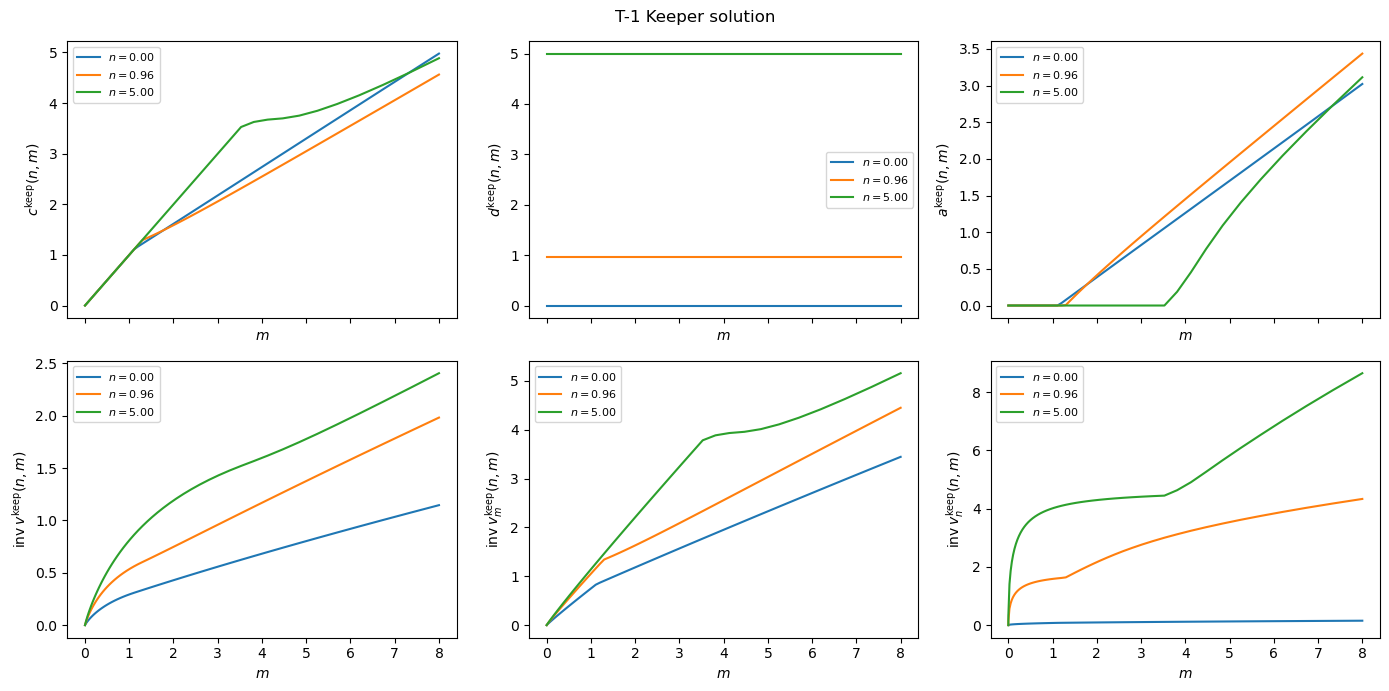

In [96]:
# --- Plot keeper solution only ---
n_show = nNrmGrid[np.linspace(1, len(nNrmGrid) - 1, 3, dtype=int)]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
funcs = [
    (cFuncKeep, r"$c^{\mathrm{keep}}(n,m)$"),
    (dFuncKeep, r"$d^{\mathrm{keep}}(n,m)$"),
    (aFuncKeep, r"$a^{\mathrm{keep}}(n,m)$"),
    (inv_vFuncKeep, r"$\mathrm{inv}\,v^{\mathrm{keep}}(n,m)$"),
    (inv_vPFuncKeep, r"$\mathrm{inv}\,v_m^{\mathrm{keep}}(n,m)$"),
    (inv_vPDFuncKeep, r"$\mathrm{inv}\,v_n^{\mathrm{keep}}(n,m)$"),
]
for ax, (func, ylab) in zip(axes.ravel(), funcs):
    for n0 in n_show:
        n_vec = np.full_like(mNrmGrid, n0, dtype=float)
        ax.plot(mNrmGrid, func(n_vec, mNrmGrid), label=fr"$n={n0:.2f}$")
    ax.set_ylabel(ylab)
    ax.set_xlabel(r"$m$")
    ax.legend(fontsize=8)

fig.suptitle("T-1 Keeper solution")
fig.tight_layout()
plt.show()


### Adjuster solution (root-finding + FUES), once per price node

Price-modified FOC residual (MaintCost=OpCost=0; see appendix eq.~(price foc)):
$$0 = u_d(c,d) - p_k\,\mathfrak{v}_c'(d,a) + \mathfrak{v}_d'(d,a),\quad c = u_c^{-1}(\mathfrak{v}_c'(d,a)),$$
with price-contingent liquidity $\ell^{(k)}=c+p_k\,d+a$. Candidate roots are refined with `FUES_allPol` separately for each $p_k$.


In [97]:
# ===== Adjuster: FOC roots + FUES_allPol, once per price node =====
# FOC: 0 = u_d(c,d) - p_k * v_c'(d,a) + v_d'(d,a), with c from u_c^{-1}(v_c')
# Liquidity: ell = c + p_k * d + a

def rootfinding_function(a, d, price):
    """Price-modified FOC residual in a for fixed d (vectorized over a)."""
    a = np.atleast_1d(np.asarray(a, dtype=float))
    d = np.atleast_1d(np.asarray(d, dtype=float))
    if d.size == 1:
        d = np.full_like(a, float(np.asarray(d).ravel()[0]))
    eop1 = EndOfPrdvPOneFunc(d, a)
    eopd = EndOfPrdvPDFunc(d, a)
    c = CRRAutilityP_inv_njit(eop1, d, alpha, d_ubar, CRRA)
    return CRRAutilityPD(c, d) - price * eop1 + eopd

a_min, a_max = float(aNrmGrid[0]), float(aNrmGrid[-1])
N_scan = 400
dNrmGridAdj = construct_grid(dNrmGrid[0], dNrmGrid[-1], len(xNrmGrid), grid_type, NestFac)
BoroCnstNat1D = 0.0  # a underbar / LTV = 0

# Per-price 1-D policy functions and grids (after FUES)
cFuncAdj_list = []
dFuncAdj_list = []
aFuncAdj_list = []
inv_vFuncAdj_1d_list = []
vFuncAdj_list = []
vPFuncAdj_list = []
x_upper_list = []

for i_p, p0 in enumerate(PriceShkVals):
    aAdj_list, cAdj_list, xAdj_list, dAdj_list, vAdj_list = [], [], [], [], []

    for d_aux in dNrmGridAdj:
        a_root = find_roots_in_interval(
            lambda a, d, _p=p0: rootfinding_function(a, d, _p), a_min, a_max, d_aux, N_scan
        )
        if a_root.size == 0:
            continue
        a_root = a_root[a_root >= -1e-8]
        if a_root.size == 0:
            continue
        d_0 = np.full_like(a_root, d_aux)
        c_0 = CRRAutilityP_inv_njit(EndOfPrdvPOneFunc(d_0, a_root), d_0, alpha, d_ubar, CRRA)
        x_0 = a_root + p0 * d_0 + c_0  # price-contingent liquidity
        v_0 = CRRAutility(c_0, d_0) + EndOfPrdvFunc(d_0, a_root)
        aAdj_list.append(a_root)
        cAdj_list.append(c_0)
        xAdj_list.append(x_0)
        dAdj_list.append(d_0)
        vAdj_list.append(v_0)

    aAdj_array = np.concatenate(aAdj_list) if aAdj_list else np.array([])
    cAdj_array = np.concatenate(cAdj_list) if cAdj_list else np.array([])
    xAdj_array = np.concatenate(xAdj_list) if xAdj_list else np.array([])
    dAdj_array = np.concatenate(dAdj_list) if dAdj_list else np.array([])
    vAdj_array = np.concatenate(vAdj_list) if vAdj_list else np.array([])
    print(f"p[{i_p}]={p0:.4f}: FOC roots = {len(xAdj_array)}")

    xAdj_upper, vAdj_upper, cAdj_upper, dAdj_upper, aAdj_upper, _ = FUES_allPol(
        xAdj_array, vAdj_array, cAdj_array, dAdj_array, aAdj_array, b=BoroCnstNat1D
    )
    inv_vAdj_upper = utility_inv(vAdj_upper, CRRA)
    print(f"  FUES kept {len(xAdj_upper)} (removed {len(xAdj_array) - len(xAdj_upper)})")

    xAdj_upper[0] = np.round(xAdj_upper[0], decimals=3)
    dAdj_upper[0] = np.round(dAdj_upper[0], decimals=3)
    aAdj_upper[0] = np.round(aAdj_upper[0], decimals=3)
    cAdj_upper[0] = np.round(cAdj_upper[0], decimals=3)
    inv_vAdj_upper[0] = np.round(inv_vAdj_upper[0], decimals=3)

    x_upper = np.append(BoroCnstNat1D, xAdj_upper)
    d_upper = np.append(0.0, dAdj_upper)
    c_upper = np.append(0.0, cAdj_upper)
    a_upper = np.append(BoroCnstNat1D, aAdj_upper)
    inv_v_upper = np.append(0.0, inv_vAdj_upper)

    while len(x_upper) > 2 and (
        c_upper[-1] < c_upper[-2] or d_upper[-1] < d_upper[-2] or inv_v_upper[-1] < inv_v_upper[-2]
    ):
        x_upper, c_upper, d_upper, a_upper, inv_v_upper = (
            x_upper[:-1], c_upper[:-1], d_upper[:-1], a_upper[:-1], inv_v_upper[:-1]
        )

    cFuncAdj_p = LinearFast(c_upper, [x_upper])
    dFuncAdj_p = LinearFast(d_upper, [x_upper])
    aFuncAdj_p = LinearFast(a_upper, [x_upper])
    inv_vFuncAdj_1d_p = LinearFast(inv_v_upper, [x_upper])
    vFuncAdj_p = ValueFuncCRRA(inv_vFuncAdj_1d_p, CRRA)
    vPFuncAdj_p = MargValueFuncCRRA_dur(cFuncAdj_p, dFuncAdj_p, alpha, d_ubar, CRRA)

    cFuncAdj_list.append(cFuncAdj_p)
    dFuncAdj_list.append(dFuncAdj_p)
    aFuncAdj_list.append(aFuncAdj_p)
    inv_vFuncAdj_1d_list.append(inv_vFuncAdj_1d_p)
    vFuncAdj_list.append(vFuncAdj_p)
    vPFuncAdj_list.append(vPFuncAdj_p)
    x_upper_list.append(x_upper)

# Representative (p≈1) 1-D functions for quick plots / API parity with baseline notebook
i_p0 = int(np.argmin(np.abs(PriceShkVals - 1.0)))
cFuncAdj = cFuncAdj_list[i_p0]
dFuncAdj = dFuncAdj_list[i_p0]
aFuncAdj = aFuncAdj_list[i_p0]
inv_vFuncAdj_1d = inv_vFuncAdj_1d_list[i_p0]
vFuncAdj = vFuncAdj_list[i_p0]
vPFuncAdj = vPFuncAdj_list[i_p0]
x_upper = x_upper_list[i_p0]

print(f"Adjuster 1-D functions built for {nPrice} prices (rep. p={PriceShkVals[i_p0]:.4f}).")


p[0]=0.8660: FOC roots = 45
  FUES kept 45 (removed 0)
p[1]=0.9436: FOC roots = 43
  FUES kept 43 (removed 0)
p[2]=0.9951: FOC roots = 43
  FUES kept 43 (removed 0)
p[3]=1.0495: FOC roots = 43
  FUES kept 43 (removed 0)
p[4]=1.1458: FOC roots = 42
  FUES kept 42 (removed 0)
Adjuster 1-D functions built for 5 prices (rep. p=0.9951).


Mapped adjuster onto (p,n,m) = (5, 40, 50)


C:\Users\adria\AppData\Local\Temp\ipykernel_11500\2401902331.py:73: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)


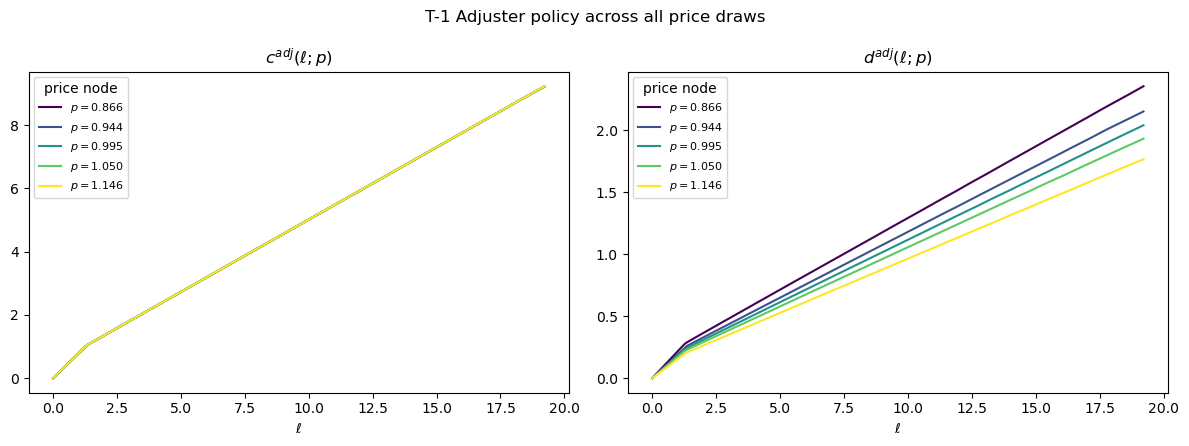

In [98]:
# Map adjuster onto (p, n, m) for the later price-weighted combine step
# Budget: a = ell - c - p*d  (not ell - c - d)
shape_nm = (nPrice, len(nNrmGrid), len(mNrmGrid))
cFuncAdj_NM_arr = np.zeros(shape_nm)
dFuncAdj_NM_arr = np.zeros(shape_nm)
aFuncAdj_NM_arr = np.zeros(shape_nm)
inv_vFuncAdj_NM_arr = np.zeros(shape_nm)
vPFuncAdj_NM_arr = np.zeros(shape_nm)
vPDFuncAdj_NM_arr = np.zeros(shape_nm)

for i_p, p0 in enumerate(PriceShkVals):
    for i_n, n0 in enumerate(nNrmGrid):
        n_aux = np.full(len(mNrmGrid), n0)
        tau_nm = tau_func(n_aux + mNrmGrid)
        x_aux = np.clip(mNrmGrid + (1.0 - tau_nm) * n_aux, 0.0, None)
        c_i = np.maximum(cFuncAdj_list[i_p](x_aux), 0.0)
        d_i = np.maximum(dFuncAdj_list[i_p](x_aux), 0.0)
        cFuncAdj_NM_arr[i_p, i_n, :] = c_i
        dFuncAdj_NM_arr[i_p, i_n, :] = d_i
        aFuncAdj_NM_arr[i_p, i_n, :] = np.maximum(x_aux - c_i - p0 * d_i, 0.0)
        inv_vFuncAdj_NM_arr[i_p, i_n, :] = inv_vFuncAdj_1d_list[i_p](x_aux)
        vPFuncAdj_NM_arr[i_p, i_n, :] = CRRAutilityP(c_i, d_i)
        vPDFuncAdj_NM_arr[i_p, i_n, :] = (1.0 - tau_nm) * vPFuncAdj_NM_arr[i_p, i_n, :]

# 2-D (n,m) slice at p≈1 for plot_keeper_adjuster_combined
cFuncAdj_NM = LinearFast(cFuncAdj_NM_arr[i_p0], [nNrmGrid, mNrmGrid])
dFuncAdj_NM = LinearFast(dFuncAdj_NM_arr[i_p0], [nNrmGrid, mNrmGrid])

print(f"Mapped adjuster onto (p,n,m) = {cFuncAdj_NM_arr.shape}")

# --- Overlay adjuster policies across all price draws (at a common liquidity grid) ---
x_plot = np.linspace(0.0, max(x.max() for x in x_upper_list), 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
cmap = plt.get_cmap("viridis")
for i_p, p0 in enumerate(PriceShkVals):
    color = cmap(i_p / max(nPrice - 1, 1))
    axes[0].plot(x_plot, cFuncAdj_list[i_p](x_plot), color=color, label=fr"$p={p0:.3f}$")
    axes[1].plot(x_plot, dFuncAdj_list[i_p](x_plot), color=color, label=fr"$p={p0:.3f}$")
axes[0].set_title(r"$c^{adj}(\ell; p)$")
axes[1].set_title(r"$d^{adj}(\ell; p)$")
for ax in axes:
    ax.set_xlabel(r"$\ell$")
    ax.legend(fontsize=8, title="price node")
fig.suptitle("T-1 Adjuster policy across all price draws")
fig.tight_layout()
plt.show()


### Combining solutions (search + taste + price)

For each $(p_k,\xi_j)$, choose $\varepsilon^\ast$ via directed search on
$(1-\varepsilon)v^{keep}+\varepsilon\,\xi_j\,v^{adj}(\ell;p_k)-\sigma(\varepsilon)$,
then integrate with $\mu_k^p\mu_j^\xi$.


T-1 combined done. Mean E[eps*]: 0.5532441818181819
adjusting range: 0.0 -> 1.0000000000000002


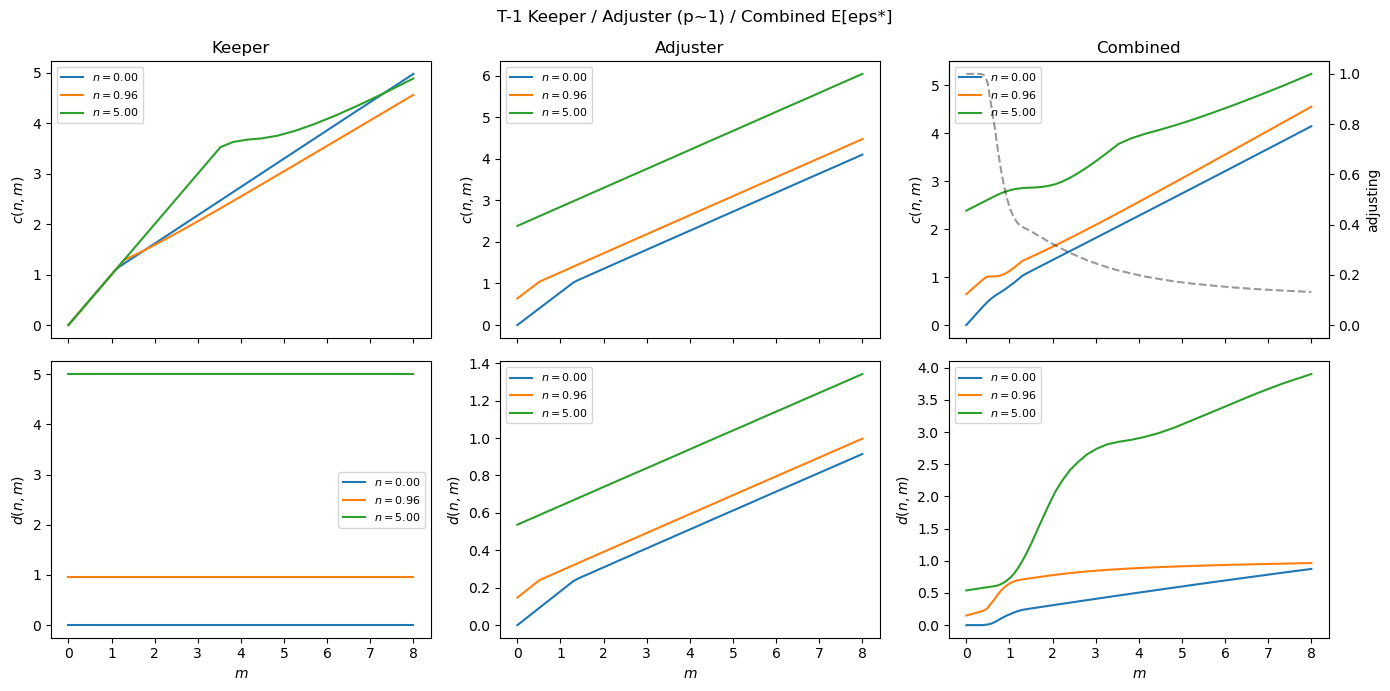

In [99]:
# ===== T-1: nested search + taste + price combine =====
cKeep_arr = np.zeros(keep_shape)
dKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    cKeep_arr[i_n, :] = np.clip(cFuncKeep(n_aux, mNrmGrid), 0.0, None)
    dKeep_arr[i_n, :] = n0

(
    cFunc_arr, dFunc_arr, aFunc_arr,
    barV_arr, vPFunc_arr, vPDFunc_arr, adjusting_arr,
) = combine_search_taste_price(
    PriceShkVals, PriceShkWeights,
    tasteShkVals, tasteShkWeights,
    cFuncAdj_NM_arr, dFuncAdj_NM_arr, aFuncAdj_NM_arr,
    inv_vFuncAdj_NM_arr, vPFuncAdj_NM_arr, vPDFuncAdj_NM_arr,
    cKeep_arr, dKeep_arr, aFuncKeep_arr,
    inv_vFuncKeep_arr, vPFuncKeep_arr, vPDFuncKeep_arr,
    nNrmGrid, mNrmGrid, SearchCost_func, e_grid, CRRA,
)

inv_vFunc_arr = utility_inv(barV_arr, CRRA)
cFunc = LinearFast(cFunc_arr, [nNrmGrid, mNrmGrid])
dFunc = LinearFast(dFunc_arr, [nNrmGrid, mNrmGrid])
inv_vFunc = LinearFast(inv_vFunc_arr, [nNrmGrid, mNrmGrid])
vFunc = ValueFuncCRRA(inv_vFunc, CRRA)
vPFunc = LinearFast(vPFunc_arr, [nNrmGrid, mNrmGrid])
vPDFunc = LinearFast(vPDFunc_arr, [nNrmGrid, mNrmGrid])
adjusting = LinearFast(adjusting_arr, [nNrmGrid, mNrmGrid])

print("T-1 combined done. Mean E[eps*]:", adjusting_arr.mean())
print("adjusting range:", adjusting_arr.min(), "->", adjusting_arr.max())

plot_keeper_adjuster_combined(
    n_show, mNrmGrid,
    cFuncKeep, dFuncKeep,
    cFuncAdj_NM, dFuncAdj_NM,
    cFunc, dFunc,
    adjusting=adjusting,
    title=f"T-1 Keeper / Adjuster (p~1) / Combined E[eps*]",
)


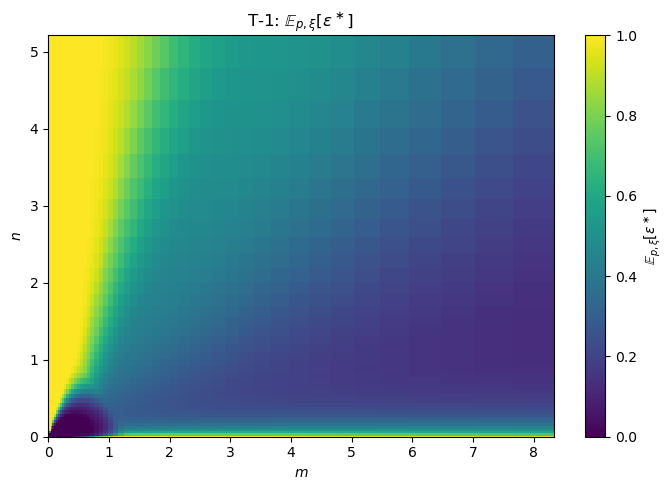

In [100]:
# --- Heatmap: E[eps*] over (n,m), T-1 ---
plot_adjusting_heatmap(
    nNrmGrid, mNrmGrid, adjusting_arr,
    title=r"T-1: $\mathbb{E}_{p,\xi}[\varepsilon^\ast]$",
    cbar_label=r"$\mathbb{E}_{p,\xi}[\varepsilon^\ast]$",
)


### Quick sanity checks

In [101]:
# Assets nonnegative; E[eps*] in [0,1]
assert np.nanmin(aFunc_arr) >= -1e-8
assert np.nanmin(adjusting_arr) >= -1e-10 and np.nanmax(adjusting_arr) <= 1.0 + 1e-10

if (SearchCost == 0.0) and (sigma_xi == 0.0) and (PriceShkStd == 0.0):
    uniq = set(np.unique(np.round(adjusting_arr, 8)))
    assert uniq.issubset({0.0, 1.0}), f"Expected hard max but got {uniq}"
    print("Hard-max shutoff check passed (all channels off).")
else:
    print(
        f"Active — taste:{sigma_xi > 0}, search:{SearchCost > 0}, price:{PriceShkStd > 0}; "
        f"adjusting in [{adjusting_arr.min():.3f}, {adjusting_arr.max():.3f}]"
    )

n_mid = float(nNrmGrid[len(nNrmGrid) // 3])
m_low = float(mNrmGrid[2])
m_high = float(mNrmGrid[-5])
print(
    f"At (n,m)=({n_mid:.3f},{m_low:.3f}): "
    f"adj={float(adjusting(n_mid, m_low)):.3f}, "
    f"c={float(cFunc(n_mid, m_low)):.3f}, d={float(dFunc(n_mid, m_low)):.3f}"
)
print(
    f"At (n,m)=({n_mid:.3f},{m_high:.3f}): "
    f"adj={float(adjusting(n_mid, m_high)):.3f}, "
    f"c={float(cFunc(n_mid, m_high)):.3f}, d={float(dFunc(n_mid, m_high)):.3f}"
)


Active — taste:True, search:True, price:True; adjusting in [0.000, 1.000]
At (n,m)=(0.468,0.026): adj=1.000, c=0.335, d=0.078
At (n,m)=(0.468,5.701): adj=0.196, c=3.360, d=0.520
